# Mechanics 7: Rigid bodies and non-inertial frames

*Learning path: mechanics, part 7 of 7.* [Index](README.md) · Previous: [Hamiltonian mechanics and phase space](06-hamiltonian-mechanics.ipynb)

In 1851 Léon Foucault hung a 28 kg ball on a 67 m wire from the dome of the Panthéon in Paris and set it swinging.
Over the day, the plane of the swing turned slowly clockwise, once around in about 32 hours. Nothing pushed it: the
pendulum kept swinging in the same plane, and **the Earth turned underneath it**. It was the first direct proof, done
in a room, that the Earth rotates. This lesson describes motion as seen from a turning frame (the Earth, a carousel,
a spinning space station), where two extra "forces" appear, and ends with a surprise about rotating rigid bodies that
astronauts film for fun.

**Who this is for.** You have done [lesson 6](06-hamiltonian-mechanics.ipynb), or at least lessons 1 to 3.

**What you will be able to do afterwards:**

1. derive the centrifugal and Coriolis forces in a rotating frame;
2. compute how the Earth's rotation deflects falling bodies and turns Foucault's pendulum;
3. use Euler's equations for a freely rotating body and explain the tennis racket theorem.

Plan about an hour and a half.

## 1. Rotating frames

Newton's laws hold in an **inertial** frame. In a frame turning with angular velocity $\Omega$, a body's acceleration
as seen in that frame differs from the true one by two terms. Moving them to the force side, a body of mass $m$ feels,
besides the real forces,

$$F_{\text{Coriolis}} = -2m\,\Omega \times v, \qquad F_{\text{centrifugal}} = -m\,\Omega \times (\Omega \times r).$$

For a frame turning about the $z$ axis, per unit mass:

In [1]:
W = [0, 0, Om];
-2*cross(W, [vx, vy, 0]) - cross(W, cross(W, [x, y, 0]))

[Om^2*x+2*Om*vy, Om^2*y-2*Om*vx, 0]

The centrifugal part $\Omega^2(x, y)$ pushes outward, growing with distance from the axis. The Coriolis part
$2\Omega(v_y, -v_x)$ is perpendicular to the velocity: it bends every moving body to the right when the frame turns
anticlockwise, and does no work. Neither is caused by anything; both come from describing motion in the wrong
(non-inertial) frame. They are still the easiest way to compute in it.

**The Earth's rotation.** One turn per sidereal day. The centrifugal acceleration at latitude 45°, at distance
$R\cos 45°$ from the axis:

In [2]:
Om = 2*pi/(86164 s);
eval(convert(Om^2*const.Rearth*cos(45 deg), m/s^2), 3)

0.0240 m/s^2

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.024 m/s², a quarter of a percent of $g$. It is why $g$ is 0.5% smaller at the equator than at the poles (together with
the Earth's own bulge, which the same force produced), and why a plumb line does not point exactly at the Earth's
centre.

**Try this.** A space station is a ring of radius 100 m. How many turns per minute give its crew 1 g?

## 2. The Coriolis force on Earth

Drop a stone from a 100 m tower at latitude 45°. While it falls the Earth turns, and the top of the tower moves east
slightly faster than its foot, so the stone lands slightly **east** of the point straight below. Integrating the
Coriolis force over the fall gives a deflection $\tfrac13\Omega g t^3\cos\lambda$:

In [3]:
tf = sqrt(2*(100 m)/const.g);
eval(convert(Om*const.g*tf^3*cos(45 deg)/3, mm), 3)

15.5 mm

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.5 cm. Ferdinand Reich measured this in a 158 m mine shaft in Freiberg in 1831 and found 28 mm, close to the
prediction for his depth.

On a large scale the Coriolis force shapes the weather. Air flowing towards a low-pressure centre is bent to the
right in the northern hemisphere, so it ends up circling the low anticlockwise: that is the turning of every northern
hurricane. (Bathtub drains are far too small and slow for it to matter.)

## 3. Foucault's pendulum

For small swings, a pendulum at latitude $\lambda$ with frequency $\omega$ moves in the horizontal plane under
$\ddot x = -\omega^2x + 2\Omega_z\dot y$ and $\ddot y = -\omega^2y - 2\Omega_z\dot x$, where $\Omega_z = \Omega\sin\lambda$
is the part of the Earth's rotation about the local vertical. To see the effect in a short run, take $\omega = 1$
and a rotation 20 times slower, $\Omega_z = 0.05$, much faster than the Earth's but the same in kind:

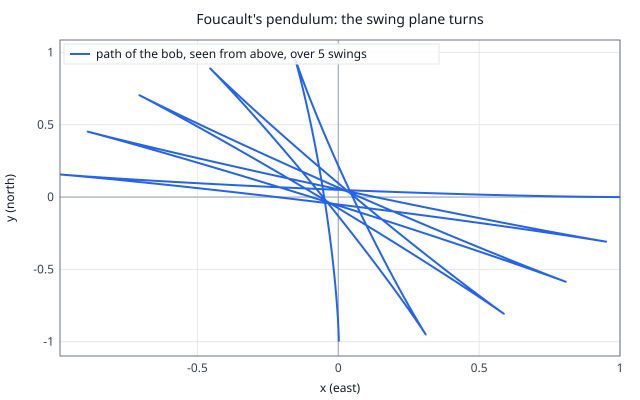

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
Oz = 0.05;
fp = [u, v, -x + 2*Oz*v, -y - 2*Oz*u];
p = odeplot(fp, [x y u v], t, [1, 0, 0, 0], 0, 31.4, [x y]);
p = legend(p, "path of the bob, seen from above, over 5 swings");
labels(title(p, "Foucault's pendulum: the swing plane turns"), "x (east)", "y (north)")

Released from rest at $x = 1$, the bob swings along a line that turns steadily, by $\Omega_z t$. Over a quarter turn
of the plane the path draws a fan of thin petals; over a full turn, a rosette. The plane turns once in $2\pi/\Omega_z$. On
the Earth, in Paris (latitude 48.85°):

In [5]:
eval(convert(2*pi/(Om*sin(48.85 deg)), h), 3)

31.8 h

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

31.8 hours, what Foucault saw. At the North Pole the plane turns once a day; on the equator, $\sin\lambda = 0$, not at
all.

**Try this.** How long does a Foucault pendulum in your city take to turn once?

## 4. Free rotation and the tennis racket theorem

A rigid body has three **principal axes**, with moments of inertia $I_1 < I_2 < I_3$. Spinning freely (no torque), its
angular velocity in the body's own frame obeys **Euler's equations**:

$$I_1\dot\omega_1 = (I_2 - I_3)\omega_2\omega_3, \quad I_2\dot\omega_2 = (I_3 - I_1)\omega_3\omega_1, \quad
I_3\dot\omega_3 = (I_1 - I_2)\omega_1\omega_2.$$

Take a body with $I = (1, 2, 3)$, like a tennis racket or a phone, and spin it about the middle axis, with a tiny
wobble:

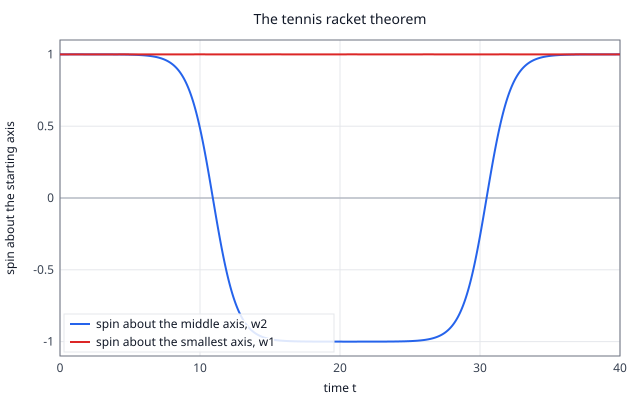

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
E = [(2 - 3)*w2*w3/1, (3 - 1)*w3*w1/2, (1 - 2)*w1*w2/3];
p = odeplot(E, [w1 w2 w3], t, [0.01, 1, 0.01], 0, 40, [t w2]);
p = show(p, odeplot(E, [w1 w2 w3], t, [1, 0.01, 0.01], 0, 40, [t w1]));
p = legend(p, "spin about the middle axis, w2", "spin about the smallest axis, w1");
labels(title(p, "The tennis racket theorem"), "time t", "spin about the starting axis")

Spun about the axis with the smallest (or the largest) moment of inertia, the body keeps spinning steadily. Spun
about the **middle** axis, the tiny wobble grows: the spin reverses completely, flips back, and repeats, a half turn of
the body each time. Throw a phone (carefully) or a tennis racket spinning about that axis and it flips over every time.
In 1985 the cosmonaut Vladimir Dzhanibekov watched a wing nut spun off a bolt do this in orbit, which is why it is also
called the Dzhanibekov effect.

Why? Near the middle axis, the small spins $\omega_1, \omega_3$ obey (linearising Euler's equations)
$\ddot\omega_1 = \frac{(I_2 - I_3)(I_1 - I_2)}{I_1I_3}\omega_2^2\,\omega_1$. The factor is positive when $I_2$ is in
the middle, so the wobble grows exponentially; it is negative for the other two axes, and the wobble just oscillates:

In [7]:
[(2 - 3)*(1 - 2)/(1*3), (1 - 2)*(3 - 1)/(2*3)]

[1/3, -1/3]

**Try this.** For the middle axis, $\omega_1$ grows like $e^{\sqrt{1/3}\,t}$. Starting from 0.01, about when does it
reach 1? Compare with the plot.

## Summary

* In a frame turning at $\Omega$, bodies feel the centrifugal force $-m\Omega\times(\Omega\times r)$ and the Coriolis
  force $-2m\Omega\times v$.
* On Earth: $g$ varies with latitude, falling bodies land east, storms turn, and a Foucault pendulum's plane turns once
  in $24\,\mathrm{h}/\sin\lambda$ (sidereal hours).
* Free rotation follows Euler's equations: stable about the axes of smallest and largest moment of inertia, unstable
  about the middle one.

That completes the mechanics path. Next, the [oscillations and waves path](../waves/README.md) builds on the harmonic
oscillator and normal modes met here.

## Exercises

1. **Merry-go-round.** You throw a ball straight at the centre of a merry-go-round turning once every 5 s, from the
   rim at 4 m/s. What deflects it, and to which side?
2. **Equator.** Using `const.Rearth`, what fraction of $g$ does the centrifugal force cancel on the equator?
3. **Eastward drop.** Derive the $\tfrac13\Omega gt^3\cos\lambda$ deflection: in the rotating frame, the Coriolis
   acceleration of a body falling at speed $gt$ is $2\Omega gt\cos\lambda$ eastward. Integrate twice.
4. **Foucault in reverse.** Start the pendulum of section 3 at the centre with a push, $u = 1$. Is the rosette
   different?
5. **Euler's equations conserve.** Check numerically that the energy $\tfrac12\sum I_i\omega_i^2$ and
   $|L|^2 = \sum I_i^2\omega_i^2$ stay constant along the flipping solution.
6. **A box.** A box of sides 1, 2 and 3 has principal moments proportional to $b^2 + c^2$ for each axis. Which axis is
   unstable?

## Hints and answers

* **Section 1, Try this.** $\Omega = \sqrt{g/R} = 0.313$ per second, about 3 turns per minute.
* **Section 3, Try this.** $23.93\,\mathrm{h}/\sin\lambda$; at 40° north about 37 hours.
* **Section 4, Try this.** $e^{0.577t} = 100$ at $t \approx 8$. In the plot $\omega_2$ starts to fall there and crosses zero near $t = 11$:
  the linear estimate holds until the wobble is no longer small.
* **Exercise 1.** The Coriolis force; seen from above with anticlockwise rotation, it curves to the right.
* **Exercise 2.** `eval(Om^2*const.Rearth/const.g, 3)` gives 0.00345, about a third of a percent.
* **Exercise 3.** $\dot v_E = 2\Omega gt\cos\lambda$, so $x_E = \tfrac13\Omega gt^3\cos\lambda$.
* **Exercise 4.** The bob now passes through the centre each swing, and the turning line draws a star of straight-ish
  strokes instead of petals.
* **Exercise 5.** Use `odedata` and compute both sums at several rows: they agree to many digits.
* **Exercise 6.** Moments proportional to $13, 10, 5$ (about the axes of length 1, 2 and 3): the middle one, $10$,
  is the axis along the side of length 2.

## Sources

1. L. Foucault, "Démonstration physique du mouvement de rotation de la Terre au moyen du pendule", *Comptes Rendus de
   l'Académie des Sciences* 32, 135–138 (1851).
2. G.-G. Coriolis, "Sur les équations du mouvement relatif des systèmes de corps", *Journal de l'École Polytechnique*
   15, 142–154 (1835).
3. L. Euler, *Theoria motus corporum solidorum seu rigidorum* (1765).
4. M. S. Ashbaugh, C. C. Chicone and R. H. Cushman, "The twisting tennis racket", *Journal of Dynamics and
   Differential Equations* 3, 67–85 (1991).
5. D. Kleppner and R. Kolenkow, *An Introduction to Mechanics*, 2nd ed., Cambridge University Press (2014), chapter 9.